In [87]:
import pandas as pd 
import numpy as np 
import sklearn
from tabulate import tabulate
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [88]:
file_path = "data/customer_data.xlsx  # raw data not included in this repo"

df1 = pd.read_excel(file_path, sheet_name="Demographic Info")  
df2 = pd.read_excel(file_path, sheet_name="Value Info")  
df3 = pd.read_excel(file_path, sheet_name="Cost")  

df_merged = pd.merge(df1, df2, on="Customer ID", how="inner")  

print(df_merged.head())

   Customer ID Title Date Of Birth Address City Contact Allowed  \
0            1    Mr    1973-06-29     Malahide               Y   
1            2    Mr    1984-07-25       Dublin               Y   
2            3    Mr    1991-05-01       Dublin               Y   
3            4    Mr    1986-11-30       Dublin               N   
4            5    Mr    1991-10-02     Limerick               Y   

    Registration Date Source of Customer  1st Order Profit  \
0 2013-01-01 00:23:00     Organic Search           8.97261   
1 2013-01-01 00:30:00         Affiliates           7.92288   
2 2013-01-01 01:09:00        Paid Social          14.06160   
3 2013-01-01 01:19:00         Affiliates          14.07672   
4 2013-01-01 01:58:00        Paid Search          22.68000   

   Subsequent Order Profit  Subsequent Orders Count  \
0                  5.30772                        1   
1                 70.15680                        7   
2                 50.80320                        7   
3   

### Channel Performance


===== Overall Metrics by Source =====
+--------------------+----------------+--------------------+------------------+-------------------------+--------------------+----------------------+---------------------------------+------------------------------------------+-----------------------------+-------------------------------------------------+----------------------+
| Source of Customer | # of Customers | Average Net Profit | Total Net Profit | Total Profit Percentage | Retention Rate (%) | Avg 1st Order Profit | Avg Profit per Subsequent Order | Avg Profit Difference (1st - Subsequent) | Avg Subsequent Order Profit | Avg Profit Difference (SUM of Subsequent - 1st) | Avg Total Promotions |
+--------------------+----------------+--------------------+------------------+-------------------------+--------------------+----------------------+---------------------------------+------------------------------------------+-----------------------------+---------------------------------------------

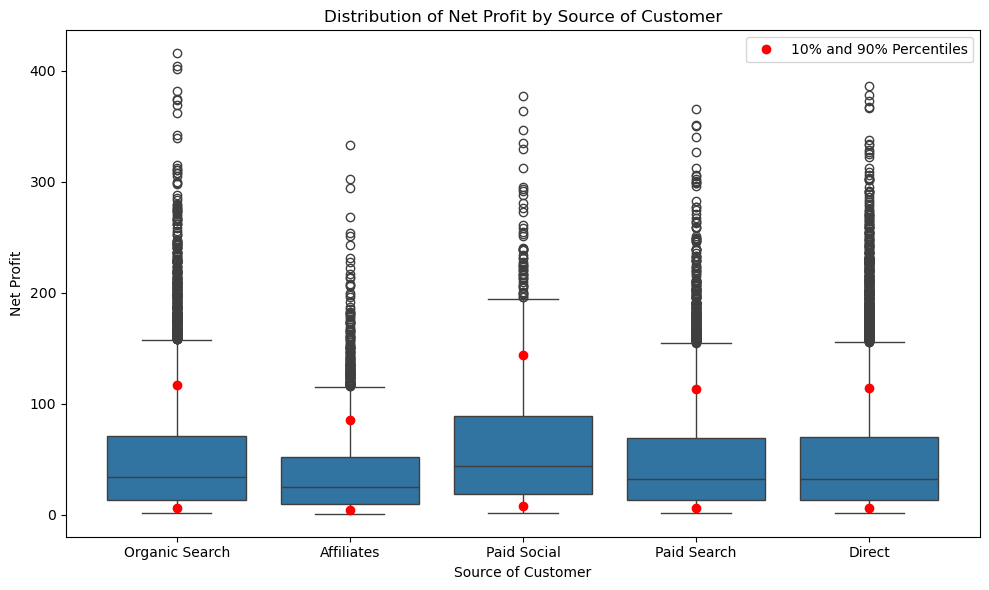


===== Monthly ROI Analysis (Jan-Mar 2013) =====
+--------------------+--------+-------------------+------------------+----------+------+-------------------+-------------------------------------+
| Source of Customer | Month  | Monthly Customers | Total Net Profit |   Cost   | ROI  | Net Profit - Cost | Profit Cost Difference per Customer |
+--------------------+--------+-------------------+------------------+----------+------+-------------------+-------------------------------------+
|     Affiliates     | 1/2013 |        868        |     28057.29     | 16421.0  | 1.71 |     11636.29      |                13.41                |
|     Affiliates     | 2/2013 |        688        |     26091.1      | 42101.0  | 0.62 |     -16009.9      |               -23.27                |
|     Affiliates     | 3/2013 |       2200        |     84161.96     | 141321.0 | 0.60 |     -57159.04     |               -25.98                |
|       Direct       | 1/2013 |       2790        |    119206.38     

In [89]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tabulate import tabulate

# =========================
# Step 0: df_merged is loaded above and contains the required fields
# =========================
# Example of loading from another source:
# df_merged = pd.read_csv('your_data.csv')
# df_merged['Registration Date'] = pd.to_datetime(df_merged['Registration Date'])

# =========================
# Step 1: Calculate net profit (promotions not subtracted)
# =========================
df_merged['net_profit'] = (
    df_merged['1st Order Profit'] 
    + df_merged['Subsequent Order Profit'] 
)

# =========================
# Step 2: Group by 'Source of Customer' and calculate various metrics
# =========================
sum_profit_source = df_merged.groupby('Source of Customer')['net_profit'].sum()
avg_profit_source = df_merged.groupby('Source of Customer')['net_profit'].mean()
count_profit_source = df_merged.groupby('Source of Customer').size()

avg_1st_order_profit = df_merged.groupby('Source of Customer')['1st Order Profit'].mean()
avg_subsequent_order_profit = df_merged.groupby('Source of Customer')['Subsequent Order Profit'].mean()
avg_profit_diff = avg_subsequent_order_profit - avg_1st_order_profit  
avg_promotions = df_merged.groupby('Source of Customer')['Total value of all promotions'].mean()

avg_profit_per_subsequent_order = (
    df_merged.groupby('Source of Customer')['Subsequent Order Profit'].sum() 
    / df_merged.groupby('Source of Customer')['Subsequent Orders Count'].sum()
)

avg_profit_diff_per = avg_1st_order_profit - avg_profit_per_subsequent_order
percentage_profit_source = (sum_profit_source / sum_profit_source.sum()) * 100

# =========================
# Step 3: Calculate retention rate for each source
# =========================
total_customers = df_merged.groupby('Source of Customer')['Customer ID'].nunique()
lost_customers = (
    df_merged[df_merged['Subsequent Orders Count'] == 0]
    .groupby('Source of Customer')['Customer ID']
    .nunique()
)
retention_rate = ((total_customers - lost_customers) / total_customers) * 100

# =========================
# Step 4: Create a DataFrame for the table output with the new metrics
# =========================
data = {
    'Source of Customer': sum_profit_source.index,
    '# of Customers': count_profit_source,
    'Average Net Profit': avg_profit_source.values.round(2),
    'Total Net Profit': sum_profit_source.values.round(0),
    'Total Profit Percentage': percentage_profit_source.values.round(2),
    'Retention Rate (%)': retention_rate.values.round(2),
    'Avg 1st Order Profit': avg_1st_order_profit.values.round(2),
    'Avg Profit per Subsequent Order': avg_profit_per_subsequent_order.values.round(2),
    'Avg Profit Difference (1st - Subsequent)': avg_profit_diff_per.values.round(2),
    'Avg Subsequent Order Profit': avg_subsequent_order_profit.values.round(2),
    'Avg Profit Difference (SUM of Subsequent - 1st)': avg_profit_diff.values.round(2),
    'Avg Total Promotions': avg_promotions.values.round(2)
}
df_table = pd.DataFrame(data)

# =========================
# Step 5: Print the formatted table
# =========================
print("\n===== Overall Metrics by Source =====")
print(tabulate(df_table, headers='keys', tablefmt='pretty', showindex=False))

# =========================
# Step 6: Visualize the distribution with a box plot and percentile markers
# =========================
plt.figure(figsize=(10, 6))
ax = sns.boxplot(x='Source of Customer', y='net_profit', data=df_merged)

sources = df_merged['Source of Customer'].unique()
for i, source in enumerate(sources):
    group = df_merged[df_merged['Source of Customer'] == source]
    q10 = group['net_profit'].quantile(0.1)
    q90 = group['net_profit'].quantile(0.9)
    ax.scatter([i, i], [q10, q90], color='red', marker='o', zorder=10)

ax.set_title('Distribution of Net Profit by Source of Customer')
ax.set_xlabel('Source of Customer')
ax.set_ylabel('Net Profit')
ax.legend(
    handles=[plt.Line2D([], [], marker='o', color='red', linestyle='None', label='10% and 90% Percentiles')],
    loc='best'
)
plt.tight_layout()
plt.show()

# =========================
# Step 7: Split by month (Jan-Mar 2013) and source, then calculate ROI
# =========================
df_merged['Reg_Year'] = df_merged['Registration Date'].dt.year
df_merged['Reg_Month'] = df_merged['Registration Date'].dt.month

df_filtered = df_merged[
    (df_merged['Reg_Year'] == 2013) & (df_merged['Reg_Month'].isin([1, 2, 3]))
]

# Aggregate by group
roi_group = (
    df_filtered
    .groupby(['Source of Customer', 'Reg_Month'])['net_profit']
    .sum()
    .reset_index()
)
roi_group.rename(columns={'net_profit': 'Total Net Profit'}, inplace=True)

# Cost data
cost_dict = {
    (1, 'Paid Search'): 41512.00,
    (1, 'Affiliates'): 16421.00,
    (2, 'Paid Search'): 61243.00,
    (2, 'Affiliates'): 42101.00,
    (3, 'Paid Search'): 84597.88,
    (3, 'Affiliates'): 141321.00
}

def get_cost(source, month):
    if (month, source) in cost_dict:
        return cost_dict[(month, source)]
    elif source in ['Direct', 'Organic Search']:
        return 0
    else:
        return np.nan

roi_group['Cost'] = roi_group.apply(
    lambda x: get_cost(x['Source of Customer'], x['Reg_Month']), axis=1
)

def compute_roi(net_profit, cost):
    if pd.isna(cost):
        return np.nan
    elif cost == 0:
        return float('inf') if net_profit > 0 else 0
    else:
        return net_profit / cost

roi_group['ROI'] = roi_group.apply(
    lambda x: compute_roi(x['Total Net Profit'], x['Cost']), axis=1
)

# Merge customer counts
monthly_customers = (
    df_filtered
    .groupby(['Source of Customer', 'Reg_Month'])['Customer ID']
    .nunique()
    .reset_index(name='Monthly Customers')
)
roi_group = pd.merge(roi_group, monthly_customers, on=['Source of Customer','Reg_Month'], how='left')

# Profit minus cost metrics
roi_group['Net Profit - Cost'] = roi_group['Total Net Profit'] - roi_group['Cost']
roi_group['Profit Cost Difference per Customer'] = roi_group.apply(
    lambda r: (r['Net Profit - Cost'] / r['Monthly Customers']) if r['Monthly Customers'] !=0 else np.nan, axis=1
)

# Formatting
month_map = {1: '1/2013', 2: '2/2013', 3: '3/2013'}
roi_group['Month'] = roi_group['Reg_Month'].map(month_map)
roi_group = roi_group[[
    'Source of Customer', 'Month', 'Monthly Customers',
    'Total Net Profit', 'Cost', 'ROI', 
    'Net Profit - Cost', 'Profit Cost Difference per Customer'
]]

# Special handling for the ROI column
def format_roi(val):
    if pd.isna(val):
        return 'N/A'
    elif np.isinf(val):
        return '∞' if val > 0 else '-∞'
    else:
        return f"{val:.2f}"

roi_group['ROI'] = roi_group['ROI'].apply(format_roi)
num_cols = ["Total Net Profit", "Cost", "Net Profit - Cost", "Profit Cost Difference per Customer"]
roi_group[num_cols] = roi_group[num_cols].round(2)

# Print the final table
print("\n===== Monthly ROI Analysis (Jan-Mar 2013) =====")
print(tabulate(roi_group, headers='keys', tablefmt='pretty', showindex=False))

#### In total, Direct brings in the most profit; per customer, Paid Social is the most profitable channel.

# Demographics

### Title

+-------+----------------+--------------------+------------------+-------------------------+--------------------+----------------------+-----------------------------+------------------------------------------+------------------------------------------+----------------------+---------------------------------+
| Title | # of Customers | Average Net Profit | Total Net Profit | Total Profit Percentage | Retention Rate (%) | Avg 1st Order Profit | Avg Subsequent Order Profit | Avg Profit Difference (Subsequent - 1st) | Avg Profit Difference (1st - Subsequent) | Avg Total Promotions | Avg Profit per Subsequent Order |
+-------+----------------+--------------------+------------------+-------------------------+--------------------+----------------------+-----------------------------+------------------------------------------+------------------------------------------+----------------------+---------------------------------+
| Miss  |      2635      |       37.61        |     99113.0      |    

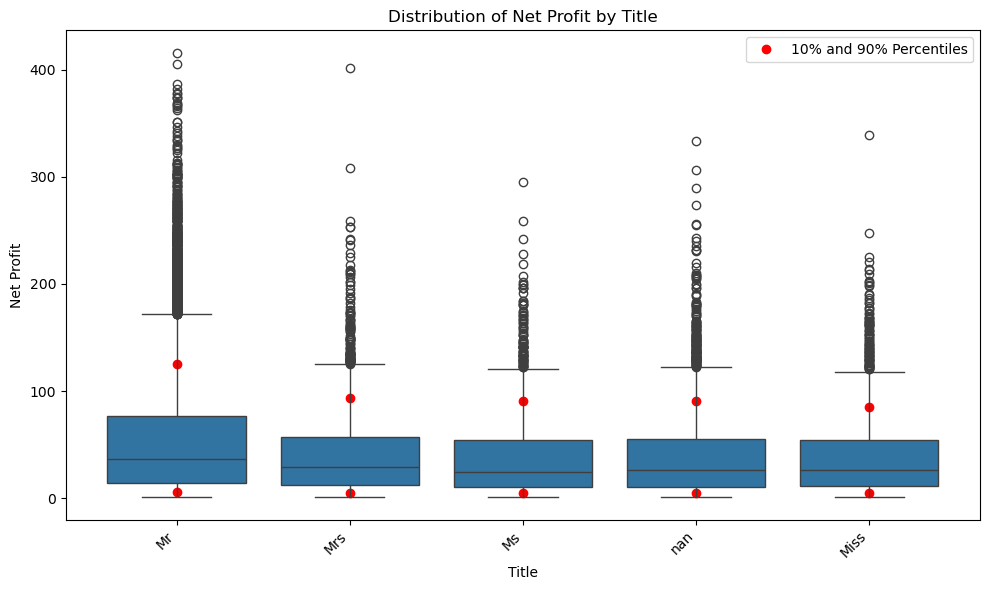

In [90]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tabulate import tabulate

# =========================
# Step 1: Calculate net profit for each row and handle missing values
# =========================
df_merged['net_profit'] = (
    df_merged['1st Order Profit'].fillna(0) 
    + df_merged['Subsequent Order Profit'].fillna(0) 
)
# Ensure net_profit is numeric
df_merged['net_profit'] = pd.to_numeric(df_merged['net_profit'], errors='coerce')

# =========================
# Step 2: Group by 'Title' and calculate various metrics
# =========================

# 1) Total & average net profit
if 'Title' not in df_merged.columns:
    raise ValueError("Column 'Title' not found in DataFrame. Please check column names.")
df_merged['Title'] = df_merged['Title'].astype(str)  # make sure values are strings

sum_profit_source = df_merged.groupby('Title')['net_profit'].sum().fillna(0)
avg_profit_source = df_merged.groupby('Title')['net_profit'].mean().fillna(0)

# 2) Average metrics
avg_1st_order_profit = df_merged.groupby('Title')['1st Order Profit'].mean().fillna(0)
avg_subsequent_order_profit = df_merged.groupby('Title')['Subsequent Order Profit'].mean().fillna(0)

#   (Subsequent - 1st)
avg_profit_diff_sub_minus_1st = avg_subsequent_order_profit - avg_1st_order_profit
#   (1st - Subsequent)
avg_profit_diff_1st_minus_sub = avg_1st_order_profit - avg_subsequent_order_profit

avg_promotions = df_merged.groupby('Title')['Total value of all promotions'].mean().fillna(0)
count_profit_source = df_merged.groupby('Title').size()

# Subsequent Order Profit per Subsequent Orders Count
subsequent_orders_count = df_merged.groupby('Title')['Subsequent Orders Count'].sum().fillna(0)
subsequent_order_profit_sum = df_merged.groupby('Title')['Subsequent Order Profit'].sum().fillna(0)

avg_profit_per_subsequent_order = pd.Series(index=sum_profit_source.index, dtype=float)
for title in sum_profit_source.index:
    if subsequent_orders_count[title] > 0:
        avg_profit_per_subsequent_order[title] = (
            subsequent_order_profit_sum[title] / subsequent_orders_count[title]
        )
    else:
        avg_profit_per_subsequent_order[title] = 0  # 0 if there are no subsequent orders

# =========================
# Step 3: Calculate percentage of total profit, handle zero total
# =========================
total_profit = sum_profit_source.sum()
if total_profit == 0:
    print("Warning: Total net profit is zero, percentages will be set to 0.")
    percentage_profit_source = pd.Series(0, index=sum_profit_source.index)
else:
    percentage_profit_source = (sum_profit_source / total_profit) * 100

# =========================
# Step 4: Calculate retention rate by Title
# =========================
if 'Customer ID' not in df_merged.columns or 'Subsequent Orders Count' not in df_merged.columns:
    raise ValueError("Required columns 'Customer ID' or 'Subsequent Orders Count' are missing.")

total_customers = df_merged.groupby('Title')['Customer ID'].nunique()
lost_customers = df_merged[df_merged['Subsequent Orders Count'] == 0].groupby('Title')['Customer ID'].nunique()

# Align indexes to avoid missing values
lost_customers = lost_customers.reindex(total_customers.index, fill_value=0)
retention_rate = ((total_customers - lost_customers) / total_customers) * 100

# =========================
# Step 5: Create a DataFrame for the table output with new metrics
# =========================
data = {
    'Title': sum_profit_source.index,
    '# of Customers': count_profit_source,
    'Average Net Profit': avg_profit_source.values.round(2),
    'Total Net Profit': sum_profit_source.values.round(0),
    'Total Profit Percentage': percentage_profit_source.values.round(2),
    'Retention Rate (%)': retention_rate.values.round(2),
    'Avg 1st Order Profit': avg_1st_order_profit.values.round(2),
    'Avg Subsequent Order Profit': avg_subsequent_order_profit.values.round(2),
    'Avg Profit Difference (Subsequent - 1st)': avg_profit_diff_sub_minus_1st.values.round(2),
    # Added: (1st - Subsequent)
    'Avg Profit Difference (1st - Subsequent)': avg_profit_diff_1st_minus_sub.values.round(2),
    'Avg Total Promotions': avg_promotions.values.round(2),
    'Avg Profit per Subsequent Order': avg_profit_per_subsequent_order.values.round(2)
}
df_table = pd.DataFrame(data)

# Print the table
print(tabulate(df_table, headers='keys', tablefmt='pretty', showindex=False))

# =========================
# Step 6: Visualize the distribution with a box plot and percentile markers
# =========================
df_plot = df_merged.dropna(subset=['net_profit', 'Title']).copy()
if df_plot.empty:
    raise ValueError("No valid data for plotting after dropping NaN values in 'net_profit' or 'Title'.")

plt.figure(figsize=(10, 6))
ax = sns.boxplot(x='Title', y='net_profit', data=df_plot)

titles = df_plot['Title'].unique()
if len(titles) == 0:
    raise ValueError("No unique titles found for plotting.")

# Mark the 10th and 90th percentiles
for i, title in enumerate(titles):
    group = df_plot[df_plot['Title'] == title]
    if not group['net_profit'].empty and not group['net_profit'].isna().all():
        q10 = group['net_profit'].quantile(0.1, interpolation='linear')
        q90 = group['net_profit'].quantile(0.9, interpolation='linear')
        if pd.notna(q10) and pd.notna(q90) and np.isfinite(q10) and np.isfinite(q90):
            ax.scatter([i, i], [q10, q90], color='red', marker='o')

ax.set_title('Distribution of Net Profit by Title')
ax.set_xlabel('Title')
ax.set_ylabel('Net Profit')
plt.xticks(rotation=45, ha='right')

ax.legend(handles=[plt.Line2D([], [], marker='o', color='red', linestyle='None', 
                              label='10% and 90% Percentiles')], loc='best')

plt.tight_layout()
plt.show()

### Address City

=== Top 10 Address Cities by Percentage (%) ===
+--------------+------------+--------------------+------------------+-------------------------+--------------------+----------------------+-----------------------------+------------------------------------------+----------------------+---------------------------------+
| Address City | # of Users | Average Net Profit | Total Net Profit | Total Profit Percentage | Retention Rate (%) | Avg 1st Order Profit | Avg Subsequent Order Profit | Avg Profit Difference (Subsequent - 1st) | Avg Total Promotions | Avg Profit per Subsequent Order |
+--------------+------------+--------------------+------------------+-------------------------+--------------------+----------------------+-----------------------------+------------------------------------------+----------------------+---------------------------------+
|    Dublin    |   21160    |       47.98        |    1015310.0     |          68.97          |       64.82        |        10.62         |   

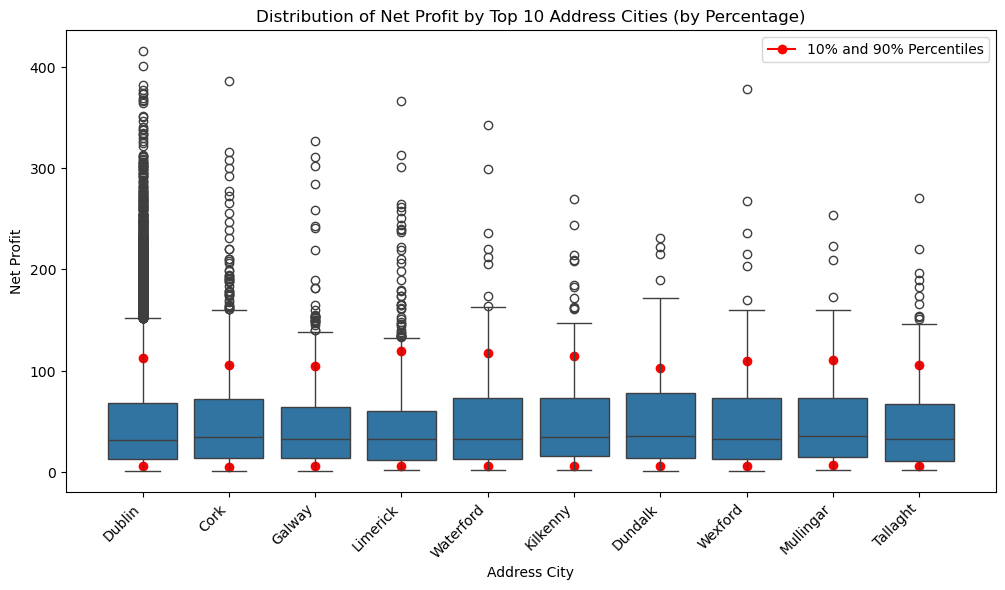

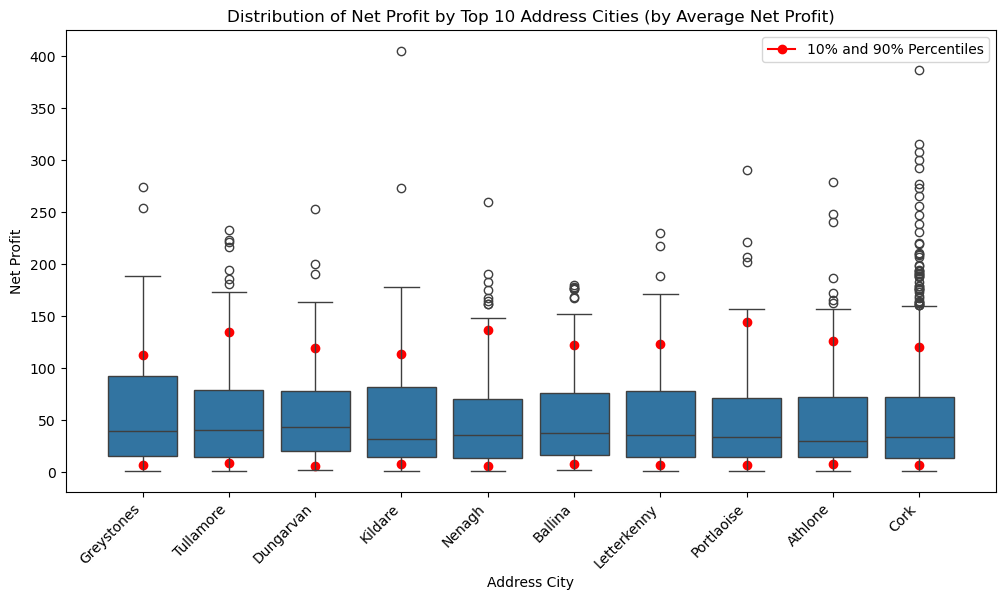

In [91]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tabulate import tabulate

# =========================
# Step 1: Calculate net profit for each row and handle missing values
# =========================
# Sum 1st Order Profit and Subsequent Order Profit only (promotions not subtracted)
df_merged['net_profit'] = (
    df_merged['1st Order Profit'].fillna(0) 
    + df_merged['Subsequent Order Profit'].fillna(0)
)

# Ensure net_profit is numeric
df_merged['net_profit'] = pd.to_numeric(df_merged['net_profit'], errors='coerce')

# =========================
# Step 2: Group by 'Address City' and calculate various metrics
# =========================
# Check for valid address city and handle missing values
if 'Address City' not in df_merged.columns:
    raise ValueError("Column 'Address City' not found in DataFrame. Please check column names.")
df_merged['Address City'] = df_merged['Address City'].astype(str)  # Ensure address cities are strings

# Total and average profits by Address City, handling NaN
sum_profit_source = df_merged.groupby('Address City')['net_profit'].sum().fillna(0)
avg_profit_source = df_merged.groupby('Address City')['net_profit'].mean().fillna(0)

# Calculate averages for the requested metrics, handling NaN
avg_1st_order_profit = df_merged.groupby('Address City')['1st Order Profit'].mean().fillna(0)
avg_subsequent_order_profit = df_merged.groupby('Address City')['Subsequent Order Profit'].mean().fillna(0)
avg_profit_diff = avg_subsequent_order_profit - avg_1st_order_profit  # Subsequent - 1st
avg_promotions = df_merged.groupby('Address City')['Total value of all promotions'].mean().fillna(0)
count_Address_city = df_merged.groupby('Address City').size()

# Calculate average Subsequent Order Profit per Subsequent Orders Count, handling NaN and zeros
subsequent_orders_count = df_merged.groupby('Address City')['Subsequent Orders Count'].sum().fillna(0)
subsequent_order_profit_sum = df_merged.groupby('Address City')['Subsequent Order Profit'].sum().fillna(0)

avg_profit_per_subsequent_order = pd.Series(index=sum_profit_source.index, dtype=float)
for city in sum_profit_source.index:
    if subsequent_orders_count[city] > 0:
        avg_profit_per_subsequent_order[city] = (
            subsequent_order_profit_sum[city] / subsequent_orders_count[city]
        )
    else:
        avg_profit_per_subsequent_order[city] = 0  # Default to 0 if no subsequent orders

# =========================
# Step 3: Calculate percentage of total profit, handle zero total
# =========================
total_profit = sum_profit_source.sum()
if total_profit == 0:
    print("Warning: Total net profit is zero, percentages will be set to 0.")
    percentage_profit_source = pd.Series(0, index=sum_profit_source.index)
else:
    percentage_profit_source = (sum_profit_source / total_profit) * 100

# =========================
# Step 4: Calculate retention rate by "Address City"
# =========================
# Make sure required columns exist
if 'Customer ID' not in df_merged.columns or 'Subsequent Orders Count' not in df_merged.columns:
    raise ValueError("Required columns 'Customer ID' or 'Subsequent Orders Count' are missing.")

# 4.1: Number of unique customers per city
total_customers = df_merged.groupby('Address City')['Customer ID'].nunique()

# 4.2: Number of unique customers with 0 subsequent orders (i.e., not retained)
lost_customers = (
    df_merged[df_merged['Subsequent Orders Count'] == 0]
    .groupby('Address City')['Customer ID']
    .nunique()
)

# Align indices to avoid missing categories
lost_customers = lost_customers.reindex(total_customers.index, fill_value=0)

# 4.3: Calculate retention rate
retention_rate = ((total_customers - lost_customers) / total_customers) * 100

# =========================
# Step 5: Create a DataFrame for the table output with new metrics
# =========================
data = {
    'Address City': sum_profit_source.index,
    '# of Users': count_Address_city,
    'Average Net Profit': avg_profit_source.values.round(2),
    'Total Net Profit': sum_profit_source.values.round(0),  
    'Total Profit Percentage': percentage_profit_source.values.round(2),  
    'Retention Rate (%)': retention_rate.values.round(2),
    'Avg 1st Order Profit': avg_1st_order_profit.values.round(2),
    'Avg Subsequent Order Profit': avg_subsequent_order_profit.values.round(2),
    'Avg Profit Difference (Subsequent - 1st)': avg_profit_diff.values.round(2),
    'Avg Total Promotions': avg_promotions.values.round(2),
    'Avg Profit per Subsequent Order': avg_profit_per_subsequent_order.values.round(2),
}
df_table = pd.DataFrame(data)

# =========================
# Step 6: Sort and select top 10 by Percentage (%) and Average Net Profit
# =========================
df_table_by_percentage = df_table.sort_values(by='Total Profit Percentage', ascending=False).head(10)
df_table_by_avg_profit = df_table.sort_values(by='Average Net Profit', ascending=False).head(10)

# Print the formatted tables for top 10 by each metric
print("=== Top 10 Address Cities by Percentage (%) ===")
print(tabulate(df_table_by_percentage, headers='keys', tablefmt='pretty', showindex=False))

print("\n=== Top 10 Address Cities by Average Net Profit ===")
print(tabulate(df_table_by_avg_profit, headers='keys', tablefmt='pretty', showindex=False))

# =========================
# Step 7: Visualize the distribution with box plots and percentile markers for top 10 cities by each metric
# =========================
df_plot = df_merged.dropna(subset=['net_profit', 'Address City']).copy()
if df_plot.empty:
    raise ValueError("No valid data for plotting after dropping NaN values in 'net_profit' or 'Address City'.")

# --- Plot 1: Distribution of Net Profit by Top 10 Address Cities (by Percentage) ---
top_cities_by_percentage = df_table_by_percentage['Address City'].tolist()
df_plot_top10_percentage = df_plot[df_plot['Address City'].isin(top_cities_by_percentage)]
if df_plot_top10_percentage.empty:
    raise ValueError("No valid data for plotting top 10 cities by Percentage after filtering.")

plt.figure(figsize=(12, 6))
ax1 = sns.boxplot(x='Address City', y='net_profit', data=df_plot_top10_percentage, 
                  order=top_cities_by_percentage)

cities_percentage = df_plot_top10_percentage['Address City'].unique()
for i, city in enumerate(cities_percentage):
    group = df_plot_top10_percentage[df_plot_top10_percentage['Address City'] == city]
    if not group['net_profit'].empty and not group['net_profit'].isna().all():
        q10 = group['net_profit'].quantile(0.1, interpolation='linear')
        q90 = group['net_profit'].quantile(0.9, interpolation='linear')
        if pd.notna(q10) and pd.notna(q90) and np.isfinite(q10) and np.isfinite(q90):
            ax1.scatter([i, i], [q10, q90], color='red', marker='o')

ax1.set_title('Distribution of Net Profit by Top 10 Address Cities (by Percentage)')
ax1.set_xlabel('Address City')
ax1.set_ylabel('Net Profit')
plt.xticks(rotation=45, ha='right')
ax1.legend(handles=[plt.Line2D([], [], marker='o', color='red', label='10% and 90% Percentiles')], loc='best')
plt.show()

# --- Plot 2: Distribution of Net Profit by Top 10 Address Cities (by Average Net Profit) ---
top_cities_by_avg_profit = df_table_by_avg_profit['Address City'].tolist()
df_plot_top10_avg_profit = df_plot[df_plot['Address City'].isin(top_cities_by_avg_profit)]
if df_plot_top10_avg_profit.empty:
    raise ValueError("No valid data for plotting top 10 cities by Average Net Profit after filtering.")

plt.figure(figsize=(12, 6))
ax2 = sns.boxplot(x='Address City', y='net_profit', data=df_plot_top10_avg_profit, 
                  order=top_cities_by_avg_profit)

cities_avg_profit = df_plot_top10_avg_profit['Address City'].unique()
for i, city in enumerate(cities_avg_profit):
    group = df_plot_top10_avg_profit[df_plot_top10_avg_profit['Address City'] == city]
    if not group['net_profit'].empty and not group['net_profit'].isna().all():
        q10 = group['net_profit'].quantile(0.1, interpolation='linear')
        q90 = group['net_profit'].quantile(0.9, interpolation='linear')
        if pd.notna(q10) and pd.notna(q90) and np.isfinite(q10) and np.isfinite(q90):
            ax2.scatter([i, i], [q10, q90], color='red', marker='o')

ax2.set_title('Distribution of Net Profit by Top 10 Address Cities (by Average Net Profit)')
ax2.set_xlabel('Address City')
ax2.set_ylabel('Net Profit')
plt.xticks(rotation=45, ha='right')
ax2.legend(handles=[plt.Line2D([], [], marker='o', color='red', label='10% and 90% Percentiles')], loc='best')
plt.show()

### Date of birth

+-----------------+------------+--------------------+------------------+-------------------------+--------------------+----------------------+-----------------------------+------------------------------------------+---------------------------------+----------------------+
|  Birth Decade   | # of Users | Average Net Profit | Total Net Profit | Total Profit Percentage | Retention Rate (%) | Avg 1st Order Profit | Avg Subsequent Order Profit | Avg Profit Difference (Subsequent - 1st) | Avg Profit per Subsequent Order | Avg Total Promotions |
+-----------------+------------+--------------------+------------------+-------------------------+--------------------+----------------------+-----------------------------+------------------------------------------+---------------------------------+----------------------+
| 1950s and Prior |    2180    |       55.81        |     121672.0     |          8.27           |       63.81        |        12.56         |            43.25            |         

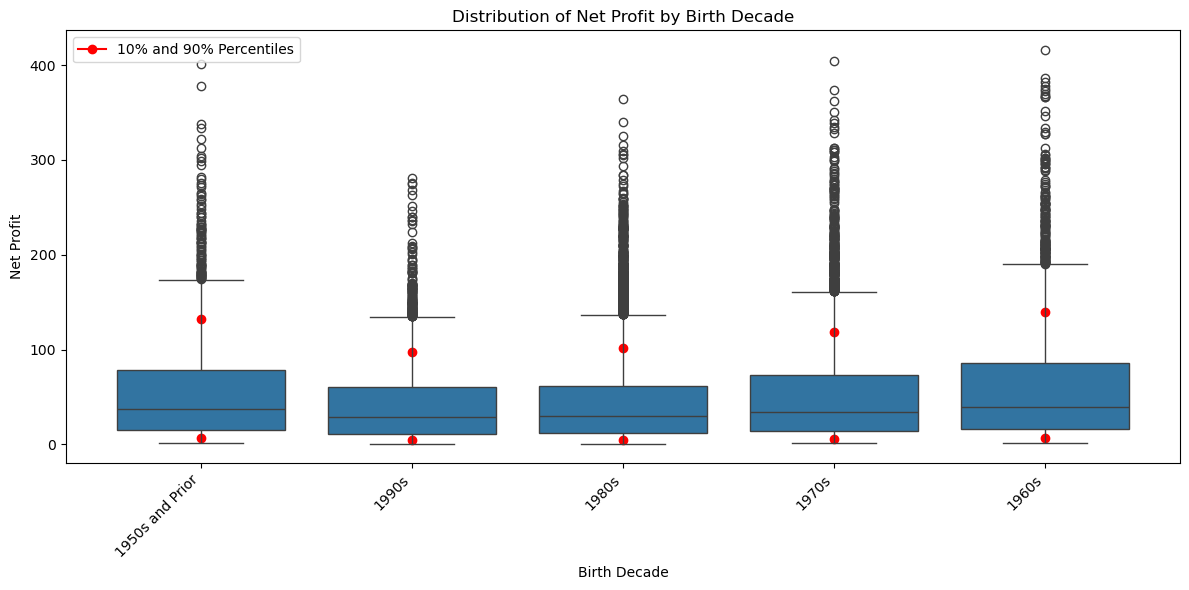

In [92]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tabulate import tabulate

# =========================
# Step 1: Calculate net profit for each row and handle missing values
# =========================
# Sum 1st Order Profit and Subsequent Order Profit only (promotions not subtracted)
df_merged['net_profit'] = (
    df_merged['1st Order Profit'].fillna(0) 
    + df_merged['Subsequent Order Profit'].fillna(0)
)

# Ensure net_profit is numeric
df_merged['net_profit'] = pd.to_numeric(df_merged['net_profit'], errors='coerce')

# =========================
# Step 2: Group by decade of birth and calculate various metrics
# =========================
# Check for valid Date Of Birth and handle missing values
if 'Date Of Birth' not in df_merged.columns:
    raise ValueError("Column 'Date Of Birth' not found in DataFrame. Please check column names.")

# Convert 'Date Of Birth' to datetime and extract decade
df_merged['Date Of Birth'] = pd.to_datetime(df_merged['Date Of Birth'], errors='coerce').fillna(pd.NaT)
df_merged['birth_decade'] = df_merged['Date Of Birth'].apply(
    lambda x: "1950s and Prior" if pd.notna(x) and x.year < 1960 else 
              f"{x.year - (x.year % 10)}s" if pd.notna(x) else pd.NA
)

# Filter out rows with NA or invalid decades directly
df_merged = df_merged[df_merged['birth_decade'].notna()].copy()

# Ensure birth_decade is a string for consistency
df_merged['birth_decade'] = df_merged['birth_decade'].astype(str)

# Group by birth decade, sorted from youngest (most recent) to oldest
decades = df_merged['birth_decade'].unique()
# Sort decades: "1950s and Prior" first, then numeric decades from youngest to oldest
decades_sorted = ["1950s and Prior"] + sorted(
    [d for d in decades if d != "1950s and Prior"], 
    key=lambda x: int(x[:-1]) if x.endswith('s') and x[:-1].isdigit() else 0,
    reverse=True
)

# Reassign birth_decade to ensure sorted order in output
df_merged['birth_decade'] = pd.Categorical(df_merged['birth_decade'], categories=decades_sorted, ordered=True)

# Total and average profits by birth decade, handling NaN
sum_profit_source = df_merged.groupby('birth_decade')['net_profit'].sum().fillna(0)
avg_profit_source = df_merged.groupby('birth_decade')['net_profit'].mean().fillna(0)
count_users = df_merged.groupby('birth_decade').size()
avg_1st_order_profit = df_merged.groupby('birth_decade')['1st Order Profit'].mean().fillna(0)
avg_subsequent_order_profit = df_merged.groupby('birth_decade')['Subsequent Order Profit'].mean().fillna(0)
avg_profit_diff = avg_subsequent_order_profit - avg_1st_order_profit
avg_promotions = df_merged.groupby('birth_decade')['Total value of all promotions'].mean().fillna(0)

subsequent_orders_count = df_merged.groupby('birth_decade')['Subsequent Orders Count'].sum().fillna(0)
subsequent_order_profit_sum = df_merged.groupby('birth_decade')['Subsequent Order Profit'].sum().fillna(0)

avg_profit_per_subsequent_order = pd.Series(index=sum_profit_source.index, dtype=float)
for decade in sum_profit_source.index:
    if subsequent_orders_count[decade] > 0:
        avg_profit_per_subsequent_order[decade] = (
            subsequent_order_profit_sum[decade] / subsequent_orders_count[decade]
        )
    else:
        avg_profit_per_subsequent_order[decade] = 0

# =========================
# Step 3: Calculate percentage of total profit, handle zero total
# =========================
total_profit = sum_profit_source.sum()
if total_profit == 0:
    print("Warning: Total net profit is zero, percentages will be set to 0.")
    percentage_profit_source = pd.Series(0, index=sum_profit_source.index)
else:
    percentage_profit_source = (sum_profit_source / total_profit) * 100

# =========================
# Step 4: Calculate retention rate by birth decade
# =========================
# Check for required columns
if 'Customer ID' not in df_merged.columns or 'Subsequent Orders Count' not in df_merged.columns:
    raise ValueError("Required columns 'Customer ID' or 'Subsequent Orders Count' are missing.")

total_customers = df_merged.groupby('birth_decade')['Customer ID'].nunique()
lost_customers = (
    df_merged[df_merged['Subsequent Orders Count'] == 0]
    .groupby('birth_decade')['Customer ID']
    .nunique()
)

# Align indices
lost_customers = lost_customers.reindex(total_customers.index, fill_value=0)
retention_rate = ((total_customers - lost_customers) / total_customers) * 100

# =========================
# Step 5: Create a DataFrame for the table output with new metrics
# =========================
data = {
    'Birth Decade': sum_profit_source.index,
    '# of Users': count_users,
    'Average Net Profit': avg_profit_source.values.round(2),
    'Total Net Profit': sum_profit_source.values.round(0),
    'Total Profit Percentage': percentage_profit_source.values.round(2),
    'Retention Rate (%)': retention_rate.values.round(2),  
    'Avg 1st Order Profit': avg_1st_order_profit.values.round(2),
    'Avg Subsequent Order Profit': avg_subsequent_order_profit.values.round(2),
    'Avg Profit Difference (Subsequent - 1st)': avg_profit_diff.values.round(2),
    'Avg Profit per Subsequent Order': avg_profit_per_subsequent_order.values.round(2),
    'Avg Total Promotions': avg_promotions.values.round(2)
}
df_table = pd.DataFrame(data)

# =========================
# Step 6: Ensure the table is sorted by birth decade (youngest to oldest, with "1950s and Prior" first)
# =========================
df_table_sorted = df_table.set_index('Birth Decade').loc[decades_sorted].reset_index()

# =========================
# Step 7: Print the formatted table for all decades
# =========================
print(tabulate(df_table_sorted, headers='keys', tablefmt='pretty', showindex=False))

# =========================
# Step 8: Visualize the distribution with a box plot and percentile markers for all decades
# =========================
df_plot = df_merged.dropna(subset=['net_profit', 'birth_decade']).copy()
if df_plot.empty:
    raise ValueError("No valid data for plotting after dropping NaN values in 'net_profit' or 'birth_decade'.")

plt.figure(figsize=(12, 6))
ax = sns.boxplot(x='birth_decade', y='net_profit', data=df_plot, order=decades_sorted)

# Get unique decades and their positions for plotting
decades_valid = [d for d in decades_sorted if d in df_plot['birth_decade'].unique()]

# Calculate and mark 10% and 90% percentiles for each decade, handle NaN
for i, decade in enumerate(decades_valid):
    group = df_plot[df_plot['birth_decade'] == decade]
    if not group['net_profit'].empty and not group['net_profit'].isna().all():
        q10 = group['net_profit'].quantile(0.1, interpolation='linear')
        q90 = group['net_profit'].quantile(0.9, interpolation='linear')
        if pd.notna(q10) and pd.notna(q90) and np.isfinite(q10) and np.isfinite(q90):
            ax.scatter([i, i], [q10, q90], color='red', marker='o')

ax.set_title('Distribution of Net Profit by Birth Decade')
ax.set_xlabel('Birth Decade')
ax.set_ylabel('Net Profit')
plt.xticks(rotation=45, ha='right')

# Add a legend to explain the red dots
ax.legend(handles=[plt.Line2D([], [], marker='o', color='red', label='10% and 90% Percentiles')], loc='best')

plt.tight_layout()
plt.show()

# Customer Behavior

### Registration Time

+-------------+----------------+--------------------+------------------+-------------------------+--------------------+----------------------+-----------------------------+------------------------------------------+---------------------------------+----------------------+
|  Time Slot  | # of Customers | Average Net Profit | Total Net Profit | Total Profit Percentage | Retention Rate (%) | Avg 1st Order Profit | Avg Subsequent Order Profit | Avg Profit Difference (Subsequent - 1st) | Avg Profit per Subsequent Order | Avg Total Promotions |
+-------------+----------------+--------------------+------------------+-------------------------+--------------------+----------------------+-----------------------------+------------------------------------------+---------------------------------+----------------------+
|  0:00-3:00  |      1911      |       47.14        |     90077.0      |          6.12           |       66.46        |         9.95         |            37.18            |         

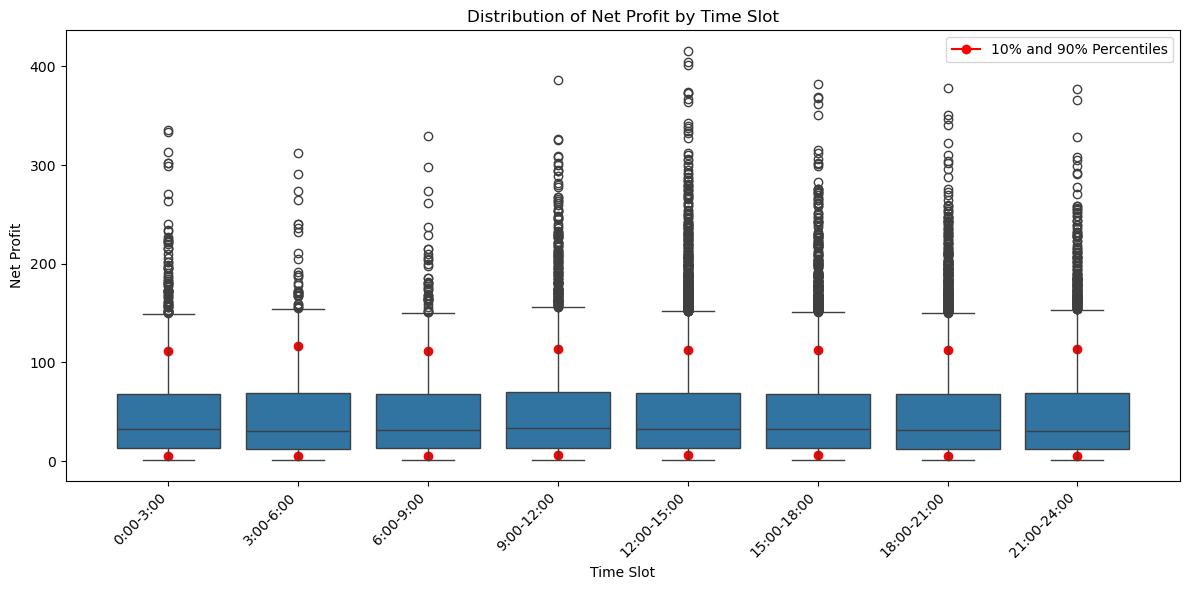

In [93]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from tabulate import tabulate

# =========================
# Step 1: Calculate net profit for each row and handle missing values
# =========================
# Sum 1st Order Profit and Subsequent Order Profit only (promotions not subtracted)
df_merged['net_profit'] = (
    df_merged['1st Order Profit'].fillna(0)
    + df_merged['Subsequent Order Profit'].fillna(0)
)

# Ensure net_profit is numeric
df_merged['net_profit'] = pd.to_numeric(df_merged['net_profit'], errors='coerce')

# =========================
# Step 2: Group by time slots of the day based on Registration Date
# =========================
if 'Registration Date' not in df_merged.columns:
    raise ValueError("Column 'Registration Date' not found in DataFrame. Please check column names.")

df_merged['Registration Date'] = pd.to_datetime(df_merged['Registration Date'], errors='coerce').fillna(pd.NaT)
df_merged['time_slot'] = df_merged['Registration Date'].apply(
    lambda x: "6:00-9:00" if pd.notna(x) and 6 <= x.hour < 9 else
              "9:00-12:00" if pd.notna(x) and 9 <= x.hour < 12 else
              "12:00-15:00" if pd.notna(x) and 12 <= x.hour < 15 else
              "15:00-18:00" if pd.notna(x) and 15 <= x.hour < 18 else
              "18:00-21:00" if pd.notna(x) and 18 <= x.hour < 21 else
              "21:00-24:00" if pd.notna(x) and 21 <= x.hour < 24 else
              "0:00-3:00" if pd.notna(x) and 0 <= x.hour < 3 else
              "3:00-6:00" if pd.notna(x) and 3 <= x.hour < 6 else pd.NA
)

# Filter out rows with NA or invalid time slots
df_merged = df_merged[df_merged['time_slot'].notna()].copy()

# Ensure time_slot is string
df_merged['time_slot'] = df_merged['time_slot'].astype(str)

# Sort time slots chronologically (by start time)
time_slots = df_merged['time_slot'].unique()
time_slots_sorted = sorted(time_slots, key=lambda x: pd.to_datetime(x.split('-')[0], format='%H:%M').hour)
df_merged['time_slot'] = pd.Categorical(df_merged['time_slot'], categories=time_slots_sorted, ordered=True)

# =========================
# Step 3: Calculate various metrics by time slot
# =========================
# Total and average net profit by time slot
sum_profit_source = df_merged.groupby('time_slot')['net_profit'].sum().fillna(0)
avg_profit_source = df_merged.groupby('time_slot')['net_profit'].mean().fillna(0)
count_customers = df_merged.groupby('time_slot').size()

# Order profit metrics
avg_1st_order_profit = df_merged.groupby('time_slot')['1st Order Profit'].mean().fillna(0)
avg_subsequent_order_profit = df_merged.groupby('time_slot')['Subsequent Order Profit'].mean().fillna(0)
avg_profit_diff = avg_subsequent_order_profit - avg_1st_order_profit
avg_promotions = df_merged.groupby('time_slot')['Total value of all promotions'].mean().fillna(0)

# Average profit per subsequent order (based on subsequent order count)
subsequent_orders_count = df_merged.groupby('time_slot')['Subsequent Orders Count'].sum().fillna(0)
subsequent_order_profit_sum = df_merged.groupby('time_slot')['Subsequent Order Profit'].sum().fillna(0)
avg_profit_per_subsequent_order = pd.Series(index=sum_profit_source.index, dtype=float)
for slot in sum_profit_source.index:
    if subsequent_orders_count[slot] > 0:
        avg_profit_per_subsequent_order[slot] = (
            subsequent_order_profit_sum[slot] / subsequent_orders_count[slot]
        )
    else:
        avg_profit_per_subsequent_order[slot] = 0

# =========================
# Step 4: Calculate percentage of total net profit
# =========================
total_profit = sum_profit_source.sum()
if total_profit == 0:
    print("Warning: Total net profit is zero, percentages will be set to 0.")
    percentage_profit_source = pd.Series(0, index=sum_profit_source.index)
else:
    percentage_profit_source = (sum_profit_source / total_profit) * 100

# =========================
# Step 4.1: Calculate Retention Rate (%) by Time Slot
# =========================
# Check required fields
if 'Customer ID' not in df_merged.columns or 'Subsequent Orders Count' not in df_merged.columns:
    raise ValueError("Required columns 'Customer ID' or 'Subsequent Orders Count' are missing.")

total_customers = df_merged.groupby('time_slot')['Customer ID'].nunique()
lost_customers = (
    df_merged[df_merged['Subsequent Orders Count'] == 0]
    .groupby('time_slot')['Customer ID']
    .nunique()
)
lost_customers = lost_customers.reindex(total_customers.index, fill_value=0)
retention_rate = ((total_customers - lost_customers) / total_customers) * 100

# =========================
# Step 5: Create a DataFrame for the table output with all metrics
# =========================
data = {
    'Time Slot': sum_profit_source.index,
    '# of Customers': count_customers,
    'Average Net Profit': avg_profit_source.values.round(2),
    'Total Net Profit': sum_profit_source.values.round(0),
    'Total Profit Percentage': percentage_profit_source.values.round(2),
    'Retention Rate (%)': retention_rate.values.round(2),
    'Avg 1st Order Profit': avg_1st_order_profit.values.round(2),
    'Avg Subsequent Order Profit': avg_subsequent_order_profit.values.round(2),
    'Avg Profit Difference (Subsequent - 1st)': avg_profit_diff.values.round(2),
    'Avg Profit per Subsequent Order': avg_profit_per_subsequent_order.values.round(2),
    'Avg Total Promotions': avg_promotions.values.round(2)
}
df_table = pd.DataFrame(data)

# =========================
# Step 6: Sort the table by time slot chronologically
# =========================
df_table_sorted = df_table.set_index('Time Slot').loc[time_slots_sorted].reset_index()

# =========================
# Step 7: Print the formatted table for all time slots
# =========================
print(tabulate(df_table_sorted, headers='keys', tablefmt='pretty', showindex=False))

# =========================
# Step 8: Visualize the distribution with a box plot and percentile markers by time slot
# =========================
df_plot = df_merged.dropna(subset=['net_profit', 'time_slot']).copy()
if df_plot.empty:
    raise ValueError("No valid data for plotting after dropping NaN values in 'net_profit' or 'time_slot'.")

plt.figure(figsize=(12, 6))
ax = sns.boxplot(x='time_slot', y='net_profit', data=df_plot, order=time_slots_sorted)

# Mark 10% and 90% percentiles for each time slot
for i, slot in enumerate(time_slots_sorted):
    slot_data = df_plot[df_plot['time_slot'] == slot]
    if not slot_data['net_profit'].empty and not slot_data['net_profit'].isna().all():
        q10 = slot_data['net_profit'].quantile(0.1, interpolation='linear')
        q90 = slot_data['net_profit'].quantile(0.9, interpolation='linear')
        if pd.notna(q10) and pd.notna(q90) and np.isfinite(q10) and np.isfinite(q90):
            ax.scatter([i, i], [q10, q90], color='red', marker='o')

ax.set_title('Distribution of Net Profit by Time Slot')
ax.set_xlabel('Time Slot')
ax.set_ylabel('Net Profit')
plt.xticks(rotation=45, ha='right')

# Add legend for the percentile markers
ax.legend(handles=[plt.Line2D([], [], marker='o', color='red', label='10% and 90% Percentiles')], loc='best')

plt.tight_layout()
plt.show()

### Contact Allowed

+------------------+----------------+-------------------------+--------------------+------------------+-------------------------+----------------------+-----------------------------+------------------------------------------+------------------------------------------+---------------------------------+----------------------+
| Retention Status | # of Customers | Customer Proportion (%) | Average Net Profit | Total Net Profit | Total Profit Percentage | Avg 1st Order Profit | Avg Subsequent Order Profit | Avg Profit Difference (Subsequent - 1st) | Avg Profit Difference (1st - Subsequent) | Avg Profit per Subsequent Order | Avg Total Promotions |
+------------------+----------------+-------------------------+--------------------+------------------+-------------------------+----------------------+-----------------------------+------------------------------------------+------------------------------------------+---------------------------------+----------------------+
|   Not Retained   |  

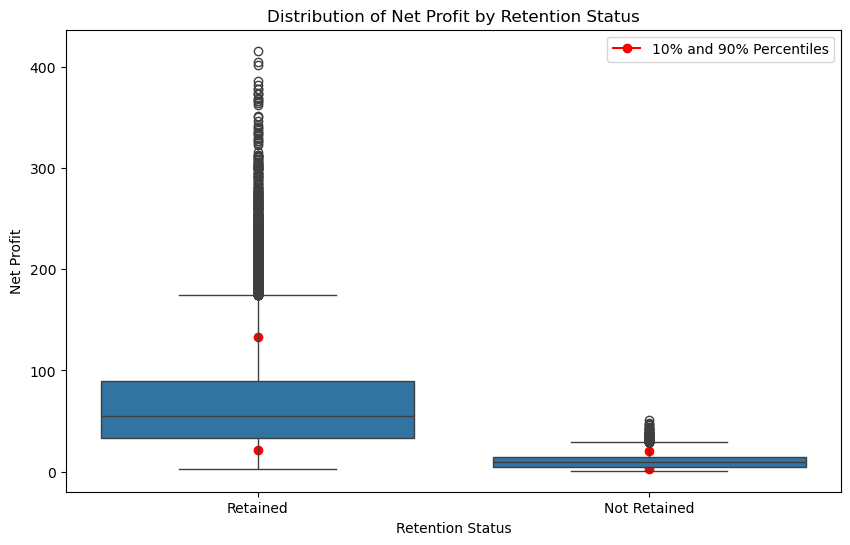

In [94]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

# --- Assume df_merged is already loaded with required columns ---
# For example:
# df_merged = pd.read_csv('customer_data.csv')

# Step 1: Calculate net profit for each row and handle missing values
df_merged['net_profit'] = (
    df_merged['1st Order Profit'].fillna(0) 
    + df_merged['Subsequent Order Profit'].fillna(0) 
)
df_merged['net_profit'] = pd.to_numeric(df_merged['net_profit'], errors='coerce')

# Step 2: Create a retention indicator column.
# A customer is "Retained" if their 'Subsequent Orders Count' > 0; otherwise "Not Retained".
df_merged['Retention Status'] = df_merged['Subsequent Orders Count'].apply(
    lambda x: 'Retained' if x > 0 else 'Not Retained'
)

# Step 3: Group by 'Retention Status' and compute various metrics
# ----------------------------------------------------------------

# (3.1) Total net profit and average net profit per retention group
sum_profit_status = df_merged.groupby('Retention Status')['net_profit'].sum()
avg_profit_status = df_merged.groupby('Retention Status')['net_profit'].mean()
count_status = df_merged.groupby('Retention Status').size()

# (3.2) Averages for order profits and promotions
avg_1st_order_profit = df_merged.groupby('Retention Status')['1st Order Profit'].mean()
avg_subsequent_order_profit = df_merged.groupby('Retention Status')['Subsequent Order Profit'].mean()
# Difference between subsequent and 1st order profit (using group averages)
avg_profit_diff = avg_subsequent_order_profit - avg_1st_order_profit  # (Subsequent - 1st)
avg_promotions = df_merged.groupby('Retention Status')['Total value of all promotions'].mean()

# (3.3) Average Subsequent Order Profit per Subsequent Orders Count
subsequent_orders_count = df_merged.groupby('Retention Status')['Subsequent Orders Count'].sum()
subsequent_order_profit_sum = df_merged.groupby('Retention Status')['Subsequent Order Profit'].sum()

avg_profit_per_subsequent_order = pd.Series(index=sum_profit_status.index, dtype=float)
for status in sum_profit_status.index:
    if subsequent_orders_count[status] > 0:
        avg_profit_per_subsequent_order[status] = (
            subsequent_order_profit_sum[status] / subsequent_orders_count[status]
        )
    else:
        avg_profit_per_subsequent_order[status] = 0

# Also, calculate the difference between the average 1st order profit and the average profit per subsequent order
avg_profit_diff_per = avg_1st_order_profit - avg_profit_per_subsequent_order  # (1st - Subsequent (per-order))

# (3.4) Percentage of total net profit by each retention group
percentage_profit_status = (sum_profit_status / sum_profit_status.sum()) * 100

# (3.5) Calculate the proportion of unique customers in each group
total_customers_all = df_merged['Customer ID'].nunique()
unique_customers_status = df_merged.groupby('Retention Status')['Customer ID'].nunique()
customer_proportion = (unique_customers_status / total_customers_all) * 100

# Step 4: Create a DataFrame for the table output with the new metrics
# --------------------------------------------------------------------
data = {
    'Retention Status': sum_profit_status.index,
    '# of Customers': count_status,
    'Customer Proportion (%)': customer_proportion.values.round(2),
    'Average Net Profit': avg_profit_status.values.round(2),
    'Total Net Profit': sum_profit_status.values.round(0),
    'Total Profit Percentage': percentage_profit_status.values.round(2),
    'Avg 1st Order Profit': avg_1st_order_profit.values.round(2),
    'Avg Subsequent Order Profit': avg_subsequent_order_profit.values.round(2),
    # The two columns below are the added difference metrics
    'Avg Profit Difference (Subsequent - 1st)': avg_profit_diff.values.round(2),
    'Avg Profit Difference (1st - Subsequent)': avg_profit_diff_per.values.round(2),
    'Avg Profit per Subsequent Order': avg_profit_per_subsequent_order.values.round(2),
    'Avg Total Promotions': avg_promotions.values.round(2)
}
df_table = pd.DataFrame(data)

# Step 5: Print the formatted table
print(tabulate(df_table, headers='keys', tablefmt='pretty', showindex=False))

# Step 6: Visualize the distribution of net profit by retention status
# --------------------------------------------------------------------
plt.figure(figsize=(10, 6))
ax = sns.boxplot(x='Retention Status', y='net_profit', data=df_merged)

statuses = df_merged['Retention Status'].unique()
for i, status in enumerate(statuses):
    group = df_merged[df_merged['Retention Status'] == status]
    q10 = group['net_profit'].quantile(0.1)
    q90 = group['net_profit'].quantile(0.9)
    ax.scatter([i, i], [q10, q90], color='red', marker='o')

ax.set_title('Distribution of Net Profit by Retention Status')
ax.set_xlabel('Retention Status')
ax.set_ylabel('Net Profit')
ax.legend(handles=[plt.Line2D([], [], marker='o', color='red', label='10% and 90% Percentiles')], loc='best')
plt.show()

### Retained Customer vs. Non-retained Customer

+------------------+----------------+-----------------------+-------------------------+--------------------+------------------+-------------------------+----------------------+---------------------------------+-----------------------------------+----------------------+
| Retention Status | # of Customers | # of Unique Customers | Customer Proportion (%) | Average Net Profit | Total Net Profit | Total Profit Percentage | Avg 1st Order Profit | Avg Profit per Subsequent Order | Avg Total Subsequent Order Profit | Avg Total Promotions |
+------------------+----------------+-----------------------+-------------------------+--------------------+------------------+-------------------------+----------------------+---------------------------------+-----------------------------------+----------------------+
|   Not Retained   |     10741      |         10741         |          35.11          |       10.59        |     113787.0     |          7.73           |        10.59         |              

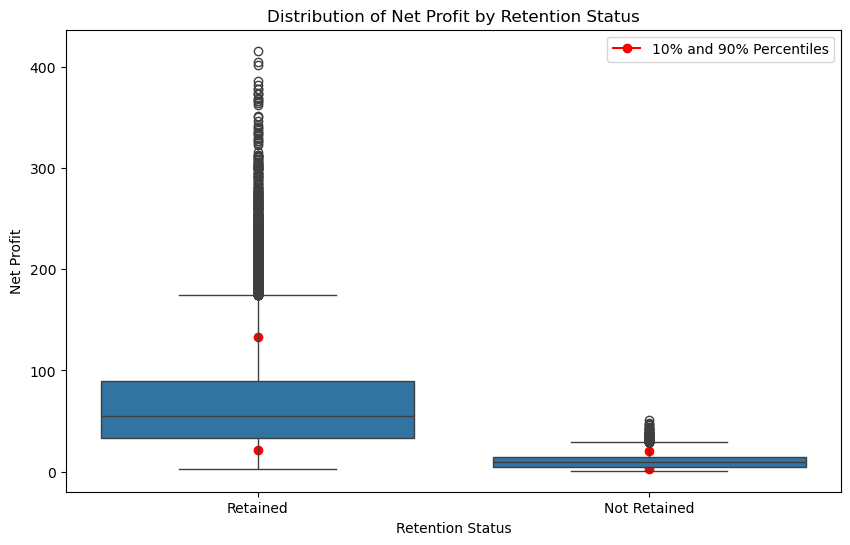

In [95]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tabulate import tabulate

# --- Assume df_merged is already loaded with required columns ---
# For example:
# df_merged = pd.read_csv('customer_data.csv')

# Step 1: Calculate net profit for each row and handle missing values
df_merged['net_profit'] = (
    df_merged['1st Order Profit'].fillna(0) 
    + df_merged['Subsequent Order Profit'].fillna(0) 
)
df_merged['net_profit'] = pd.to_numeric(df_merged['net_profit'], errors='coerce')

# Step 2: Create a retention indicator column.
# A customer is "Retained" if their 'Subsequent Orders Count' > 0; otherwise "Not Retained".
df_merged['Retention Status'] = df_merged['Subsequent Orders Count'].apply(
    lambda x: 'Retained' if x > 0 else 'Not Retained'
)

# Step 3: Group by 'Retention Status' and compute various metrics
# Total net profit and average net profit per retention group
sum_profit_status = df_merged.groupby('Retention Status')['net_profit'].sum()
avg_profit_status = df_merged.groupby('Retention Status')['net_profit'].mean()
count_status = df_merged.groupby('Retention Status').size()

# Averages for order profits and promotions
avg_1st_order_profit = df_merged.groupby('Retention Status')['1st Order Profit'].mean()
avg_subsequent_order_profit = df_merged.groupby('Retention Status')['Subsequent Order Profit'].mean()
# Difference between subsequent and 1st order profit (using group averages)
avg_profit_diff = avg_subsequent_order_profit - avg_1st_order_profit
avg_promotions = df_merged.groupby('Retention Status')['Total value of all promotions'].mean()

# Average Subsequent Order Profit per Subsequent Orders Count
subsequent_orders_count = df_merged.groupby('Retention Status')['Subsequent Orders Count'].sum()
subsequent_order_profit_sum = df_merged.groupby('Retention Status')['Subsequent Order Profit'].sum()

avg_profit_per_subsequent_order = pd.Series(index=sum_profit_status.index, dtype=float)
for status in sum_profit_status.index:
    if subsequent_orders_count[status] > 0:
        avg_profit_per_subsequent_order[status] = (
            subsequent_order_profit_sum[status] / subsequent_orders_count[status]
        )
    else:
        avg_profit_per_subsequent_order[status] = 0

# Also, calculate the difference between the average 1st order profit and the average profit per subsequent order
avg_profit_diff_per = avg_1st_order_profit - avg_profit_per_subsequent_order

# Percentage of total net profit by each retention group
percentage_profit_status = (sum_profit_status / sum_profit_status.sum()) * 100

# Additionally, calculate the proportion of unique customers in each group
total_customers_all = df_merged['Customer ID'].nunique()
unique_customers_status = df_merged.groupby('Retention Status')['Customer ID'].nunique()
customer_proportion = (unique_customers_status / total_customers_all) * 100

# Step 4: Create a DataFrame for the table output with the new metrics
data = {
    'Retention Status': sum_profit_status.index,
    '# of Customers': count_status,
    '# of Unique Customers': unique_customers_status,
    'Customer Proportion (%)': customer_proportion.values.round(2),
    'Average Net Profit': avg_profit_status.values.round(2),
    'Total Net Profit': sum_profit_status.values.round(0),
    'Total Profit Percentage': percentage_profit_status.values.round(2),
    'Avg 1st Order Profit': avg_1st_order_profit.values.round(2),
    'Avg Profit per Subsequent Order': avg_profit_per_subsequent_order.values.round(2),
    'Avg Total Subsequent Order Profit': avg_subsequent_order_profit.values.round(2),
    'Avg Total Promotions': avg_promotions.values.round(2)
}
df_table = pd.DataFrame(data)

# Step 5: Print the formatted table
print(tabulate(df_table, headers='keys', tablefmt='pretty', showindex=False))

# Step 6: Visualize the distribution of net profit by retention status
plt.figure(figsize=(10, 6))
ax = sns.boxplot(x='Retention Status', y='net_profit', data=df_merged)
statuses = df_merged['Retention Status'].unique()
for i, status in enumerate(statuses):
    group = df_merged[df_merged['Retention Status'] == status]
    q10 = group['net_profit'].quantile(0.1)
    q90 = group['net_profit'].quantile(0.9)
    ax.scatter([i, i], [q10, q90], color='red', marker='o')
ax.set_title('Distribution of Net Profit by Retention Status')
ax.set_xlabel('Retention Status')
ax.set_ylabel('Net Profit')
ax.legend(handles=[plt.Line2D([], [], marker='o', color='red', label='10% and 90% Percentiles')], loc='best')
plt.show()

##### Retained and non-retained customers differ sharply in profit, so a model that predicts who will reorder (and why) is worth building: it lets us target at-risk customers early.

In [96]:
df_merged.head()

,Customer ID,Title,Date Of Birth,Address City,Contact Allowed,Registration Date,Source of Customer,1st Order Profit,Subsequent Order Profit,Subsequent Orders Count,Total value of all promotions,net_profit,Reg_Year,Reg_Month,birth_decade,time_slot,Retention Status
0,1,Mr,1973-06-29,Malahide,Y,2013-01-01 00:23:00,Organic Search,8.97261,5.30772,1,6.600000,14.28033,2013,1,1970s,0:00-3:00,Retained
1,2,Mr,1984-07-25,Dublin,Y,2013-01-01 00:30:00,Affiliates,7.92288,70.15680,7,6.639453,78.07968,2013,1,1980s,0:00-3:00,Retained
2,3,Mr,1991-05-01,Dublin,Y,2013-01-01 01:09:00,Paid Social,14.06160,50.80320,7,0.000000,64.86480,2013,1,1990s,0:00-3:00,Retained
3,4,Mr,1986-11-30,Dublin,N,2013-01-01 01:19:00,Affiliates,14.07672,0.00000,0,0.000000,14.07672,2013,1,1980s,0:00-3:00,Not Retained
4,5,Mr,1991-10-02,Limerick,Y,2013-01-01 01:58:00,Paid Search,22.68000,68.22144,9,14.771948,90.90144,2013,1,1990s,0:00-3:00,Retained


In [97]:
import scipy.stats as stats

# STEP 1: Create an 'age' feature from 'Date Of Birth'
# Convert 'Date Of Birth' to datetime
df_merged['Date Of Birth'] = pd.to_datetime(df_merged['Date Of Birth'], errors='coerce')

# Calculate age in years using today's date as reference
reference_date = pd.to_datetime('today')
df_merged['age'] = (reference_date - df_merged['Date Of Birth']).dt.days / 365.25

# Drop the original 'Date Of Birth' column
df_merged.drop(columns=['Date Of Birth'], inplace=True)

# STEP 2: Identify categorical and numeric columns
categorical_cols = df_merged.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = df_merged.select_dtypes(exclude=['object', 'category']).columns.tolist()

# STEP 3: Remove unwanted columns from the lists
# These columns are either identifiers, raw dates, or are not desired for correlation.
unwanted = ['Customer ID', 'Registration Date', 'Retention Status',
            'Subsequent Order Profit', 'Subsequent Orders Count', 'net profit']
for col in unwanted:
    if col in numeric_cols:
        numeric_cols.remove(col)
    if col in categorical_cols:
        categorical_cols.remove(col)

print("Numeric columns for correlation:", numeric_cols)
print("Categorical columns for correlation:", categorical_cols)

df_merged['Retention Status'] = df_merged['Retention Status'].map({'Retained': 1, 'Not Retained': 0})

# STEP 4: Compute Pearson correlation for numeric columns with the target.
# Here we assume the target column is 'Retention_Status' and it is numeric (0/1)
numeric_corr = df_merged[numeric_cols].corrwith(df_merged['Retention Status'])
print("\nPearson Correlation of Numeric Columns with Retention_Status:")
print(numeric_corr)

# STEP 5: Compute Cramér's V for categorical columns with the target.
def cramers_v(x, y):
    """
    Compute Cramér's V statistic for two categorical variables.
    """
    confusion_matrix = pd.crosstab(x, y)
    chi2 = stats.chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    # Bias correction
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    return np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))

print("\nCramér's V for Categorical Columns with Retention_Status:")
for col in categorical_cols:
    if df_merged[col].nunique() > 1:
        cv = cramers_v(df_merged[col], df_merged['Retention Status'])
        print(f"{col}: {cv:.3f}")

Numeric columns for correlation: ['1st Order Profit', 'Total value of all promotions', 'net_profit', 'Reg_Year', 'Reg_Month', 'age']
Categorical columns for correlation: ['Title', 'Address City', 'Contact Allowed', 'Source of Customer', 'birth_decade', 'time_slot']

Pearson Correlation of Numeric Columns with Retention_Status:
1st Order Profit                 0.009182
Total value of all promotions    0.329459
net_profit                       0.569278
Reg_Year                              NaN
Reg_Month                        0.069005
age                             -0.011534
dtype: float64

Cramér's V for Categorical Columns with Retention_Status:
Title: 0.017
Address City: 0.008
Contact Allowed: 0.008
Source of Customer: 0.018
birth_decade: 0.000
time_slot: 0.011


### Feature choice: Subsequent Order Profit and Subsequent Orders Count are dropped because they define the target. net_profit is excluded from modeling for the same reason (it includes Subsequent Order Profit).

### Among the remaining features, Total value of all promotions has the strongest correlation with retention (0.33). Caveat: this field counts promotions redeemed through June 30, including on later orders, so part of this signal is leakage (see README, Limitations).

In [98]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# --- Assume df_merged is already loaded ---
# For example, df_merged = pd.read_csv('customer_data.csv')

# Step 1: Compute net profit
df_merged['net_profit'] = (
    df_merged['1st Order Profit'].fillna(0) +
    df_merged['Subsequent Order Profit'].fillna(0))

df_merged['net_profit'] = pd.to_numeric(df_merged['net_profit'], errors='coerce')

# Step 2: Convert grouping columns to categorical, if needed
# (assuming these columns exist from previous transformations)
for col in ['birth_decade', 'reg_group', 'time_slot']:
    if col in df_merged.columns:
        df_merged[col] = df_merged[col].astype('category')

# Step 3: Create the target variable.
# A customer is considered "Retained" if Subsequent Orders Count > 0.
df_merged['Retention_Status'] = (df_merged['Subsequent Orders Count'] > 0).astype(int)

# Step 4: Drop columns not intended for modeling.
# We'll drop Customer ID, Date Of Birth, and Registration Date.
# You might also drop any other identifiers if not needed.
drop_cols = ['Customer ID', 'Registration Date', 'Retention Status', 'Subsequent Order Profit', 'Subsequent Orders Count', 'net_profit']
X = df_merged.drop(columns = drop_cols + ['Retention_Status'])
y = df_merged['Retention_Status']

# Step 5: Automatically identify categorical and numeric columns.
# Here, we treat object and category types as categorical.
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)

# Step 6: Build the preprocessing pipeline.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Step 7: Build the full pipeline with Logistic Regression.
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

# Step 8: Split the data into 80/20 train/test sets (stratify by target)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, stratify=y, random_state=42
)

# Step 9: Train the logistic regression model.
pipeline.fit(X_train, y_train)

# Step 10: Predict and evaluate.
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

Categorical columns: ['Title', 'Address City', 'Contact Allowed', 'Source of Customer', 'birth_decade', 'time_slot']
Numeric columns: ['1st Order Profit', 'Total value of all promotions', 'Reg_Year', 'Reg_Month', 'age']
Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.85      0.63      2148
           1       0.87      0.54      0.67      3971

    accuracy                           0.65      6119
   macro avg       0.69      0.70      0.65      6119
weighted avg       0.74      0.65      0.65      6119

ROC-AUC Score: 0.7015287041479028


### Goal: find customers who will not reorder, so we optimize recall for class 0. Giving an extra offer to a customer who would have reordered anyway costs less than missing an at-risk customer.

### Next step: tune the decision threshold to push class-0 recall higher (e.g., 90%+).

# Tree Based Model

In [100]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier  # tree-based model
from sklearn.metrics import classification_report, roc_auc_score
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
# --- Assume df_merged is already loaded ---
# For example, df_merged = pd.read_csv('customer_data.csv')

# Step 1: Compute net profit
df_merged['net_profit'] = (
    df_merged['1st Order Profit'].fillna(0) +
    df_merged['Subsequent Order Profit'].fillna(0) -
    df_merged['Total value of all promotions'].fillna(0)
)
df_merged['net_profit'] = pd.to_numeric(df_merged['net_profit'], errors='coerce')

# Step 2: Convert grouping columns to categorical, if needed
# (assuming these columns exist from previous transformations)
for col in ['birth_decade', 'reg_group', 'time_slot']:
    if col in df_merged.columns:
        df_merged[col] = df_merged[col].astype('category')

# Step 3: Create the target variable.
# A customer is considered "Retained" if Subsequent Orders Count > 0.
df_merged['Retention_Status'] = (df_merged['Subsequent Orders Count'] > 0).astype(int)

# Step 4: Drop columns not intended for modeling.
# We'll drop Customer ID, Date Of Birth, and Registration Date.
# You might also drop any other identifiers if not needed.
drop_cols = ['Customer ID', 'Registration Date', 'Retention Status', 'Subsequent Order Profit', 'Subsequent Orders Count', 'net_profit', 'age',]
X = df_merged.drop(columns = drop_cols + ['Retention_Status'])
y = df_merged['Retention_Status']

# Step 5: Automatically identify categorical and numeric columns
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

# Step 6: Build the preprocessing pipeline
# Tree models do not need scaling; keeping it does not change results
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),  # StandardScaler optional for trees
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

# Step 7: Random forest model
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,        # number of trees
        max_depth=5,             # limit overfitting
        class_weight='balanced', # handle class imbalance
        random_state=42
    ))
])

# Step 8: Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Step 9: Train the tree based model.
pipeline.fit(X_train, y_train)

# Step 10: Predict and evaluate.
y_pred = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

print("Classification Report:")
print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

# ----------------------------------------------------------
# Retrieve and display feature importances
# ----------------------------------------------------------
rf_model = pipeline.named_steps['classifier']  # The RandomForestClassifier
ct = pipeline.named_steps['preprocessor']      # The ColumnTransformer

# 1) Numeric feature names come from numeric_cols directly
# 2) Categorical feature names come from the OneHotEncoder
ohe = ct.transformers_[1][1]  # This is the OneHotEncoder
cat_feature_names = ohe.get_feature_names_out(categorical_cols)

# Combine them in the same order as the ColumnTransformer output:
all_feature_names = numeric_cols + list(cat_feature_names)

importances = rf_model.feature_importances_
# Pair them up and sort by importance descending
feat_imp = sorted(zip(all_feature_names, importances), key=lambda x: x[1], reverse=True)

print("\n=== Feature Importances ===")
for feat, imp in feat_imp:
    print(f"{feat}: {imp:.2f}")

Classification Report:
              precision    recall  f1-score   support

           0       0.48      0.95      0.63      2148
           1       0.94      0.43      0.59      3971

    accuracy                           0.61      6119
   macro avg       0.71      0.69      0.61      6119
weighted avg       0.78      0.61      0.61      6119

ROC-AUC Score: 0.7598850980596288

=== Feature Importances ===
Total value of all promotions: 0.65
Reg_Month: 0.10
1st Order Profit: 0.04
Title_Mr: 0.01
Source of Customer_Paid Search: 0.01
time_slot_3:00-6:00: 0.01
birth_decade_1980s: 0.01
Title_Miss: 0.01
Source of Customer_Paid Social: 0.01
Contact Allowed_N: 0.01
Source of Customer_Direct: 0.01
Title_nan: 0.00
birth_decade_1970s: 0.00
time_slot_15:00-18:00: 0.00
Address City_Letterkenny: 0.00
Title_Mrs: 0.00
Source of Customer_Organic Search: 0.00
Source of Customer_Affiliates: 0.00
Address City_Kilkenny: 0.00
Title_Ms: 0.00
birth_decade_1960s: 0.00
birth_decade_1950s and Prior: 0.00
time

### XGBoost

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from imblearn.pipeline import Pipeline  # Use imblearn's Pipeline for SMOTE integration
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, roc_auc_score, recall_score, make_scorer
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# -------------------------------
# 1) PREPARE YOUR DATA
# -------------------------------
# Assume df_merged is already loaded, e.g.:
# df_merged = pd.read_csv('customer_data.csv')

# a) Compute net_profit
df_merged['net_profit'] = (
    df_merged['1st Order Profit'].fillna(0) +
    df_merged['Subsequent Order Profit'].fillna(0) -
    df_merged['Total value of all promotions'].fillna(0)
)
df_merged['net_profit'] = pd.to_numeric(df_merged['net_profit'], errors='coerce')

# b) Convert grouping columns to categorical (if needed)
for col in ['birth_decade', 'reg_group', 'time_slot']:
    if col in df_merged.columns:
        df_merged[col] = df_merged[col].astype('category')

# c) Define the target variable.
# A customer is considered retained if Subsequent Orders Count > 0.
df_merged['Retention_Status'] = (df_merged['Subsequent Orders Count'] > 0).astype(int)

# d) Drop columns not used for modeling.
# Note: We drop identifiers, raw dates, and other columns that should not be used as features.
drop_cols = [
    'Customer ID', 'Registration Date', 'Retention Status',
    'Subsequent Order Profit', 'Subsequent Orders Count',
    'net_profit', 'age'
]
X = df_merged.drop(columns=drop_cols + ['Retention_Status'])
y = df_merged['Retention_Status']

# -------------------------------
# 2) IDENTIFY FEATURE TYPES
# -------------------------------
# Automatically get lists of categorical and numeric columns.
categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = X.select_dtypes(exclude=['object', 'category']).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numeric columns:", numeric_cols)

# -------------------------------
# 3) BUILD THE PREPROCESSING PIPELINE
# -------------------------------
# For XGBoost, we one-hot encode categorical features.
# IMPORTANT: Use sparse_output=False so that the encoder returns a dense matrix (required by SMOTE).
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

# -------------------------------
# 4) DEFINE A CUSTOM SCORER FOR RECALL OF CLASS 0
# -------------------------------
def recall_class0(y_true, y_pred):
    """
    Compute recall for the negative class (label 0).
    """
    return recall_score(y_true, y_pred, pos_label=0)

custom_scorer = make_scorer(recall_class0, greater_is_better=True)

# -------------------------------
# 5) BUILD THE PIPELINE WITH SMOTE AND XGBOOST
# -------------------------------
pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        use_label_encoder=False,
        eval_metric='logloss',
        random_state=42,
        scale_pos_weight=2  # class weight
    ))
])

# -------------------------------
# 6) SPLIT DATA INTO TRAIN/TEST SETS
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# -------------------------------
# 7) HYPERPARAMETER TUNING WITH RANDOMIZEDSEARCHCV
# -------------------------------
param_distributions = {
    'classifier__n_estimators': [100, 200, 300, 500],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__max_depth': [3, 5, 6, 8],
    'classifier__subsample': [0.8, 1.0],
    'classifier__colsample_bytree': [0.8, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_distributions,
    n_iter=10,
    cv=3,
    scoring=custom_scorer,   # still optimizing recall for class 0
    random_state=42,
    verbose=2
)

random_search.fit(X_train, y_train)
print("Best Params:", random_search.best_params_)
print("Best Score (Recall for class 0):", random_search.best_score_)

# Use the best estimator for further evaluation.
best_pipeline = random_search.best_estimator_

# -------------------------------
# 8) PREDICT AND EVALUATE THE BEST MODEL
# -------------------------------
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]

print("\n=== Classification Report (Test) ===")
print(classification_report(y_test, y_pred))
print("ROC-AUC Score:", roc_auc_score(y_test, y_proba))

# -------------------------------
# 9) (Optional) FEATURE IMPORTANCE ANALYSIS
# -------------------------------
# Get feature names from the preprocessor:
ohe = best_pipeline.named_steps['preprocessor'].transformers_[1][1]  # OneHotEncoder instance
cat_feature_names = ohe.get_feature_names_out(categorical_cols)
all_feature_names = numeric_cols + list(cat_feature_names)
importances = best_pipeline.named_steps['classifier'].feature_importances_
feat_imp = sorted(zip(all_feature_names, importances), key=lambda x: x[1], reverse=True)
print("\n=== Feature Importances (Top 20) ===")
for feat, imp in feat_imp[:20]:
    print(f"{feat}: {imp:.4f}")

Categorical columns: ['Title', 'Address City', 'Contact Allowed', 'Source of Customer', 'birth_decade', 'reg_group', 'time_slot']
Numeric columns: ['1st Order Profit', 'Total value of all promotions']
Fitting 3 folds for each of 10 candidates, totalling 30 fits


Best Params: {'classifier__subsample': 1.0, 'classifier__n_estimators': 100, 'classifier__max_depth': 8, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 1.0}
Best Score (Recall for class 0): 0.5149550618945015

=== Classification Report (Test) ===
              precision    recall  f1-score   support

           0       0.69      0.53      0.60      2148
           1       0.77      0.87      0.82      3971

    accuracy                           0.75      6119
   macro avg       0.73      0.70      0.71      6119
weighted avg       0.75      0.75      0.74      6119

ROC-AUC Score: 0.8269540410996484

=== Feature Importances (Top 20) ===
Total value of all promotions: 0.1825
Address City_Dublin: 0.0450
1st Order Profit: 0.0271
reg_group_2/13/2013 - 3/13/2013: 0.0235
time_slot_6:00-9:00: 0.0200
Address City_Drogheda: 0.0189
Address City_Waterford: 0.0185
reg_group_1/13/2013 - 2/13/2013: 0.0182
time_slot_3:00-6:00: 0.0175
time_slot_0:00-3:00: 0.0173
Source of Customer